# 04 · kNN, linear probe, few-shot

**Goal.** Measure the frozen features. The backbone weights do not move. A cosine kNN (k = 20, temperature-weighted, as in the DINO eval) and a logistic-regression probe read the cache from notebook 03.

**What you will see.** Accuracy, balanced accuracy and macro F1, with a 1,000× bootstrap over test tiles. The probe is repeated at 1%, 10% and 100% of the training labels. Then a confusion matrix and a UMAP per backbone.

**Runtime.** About 10 minutes once features are cached. The bootstrap resamples predictions; it does not refit a model a thousand times.

**Talking point.** Slides 17–20. This is the "labels are expensive" curve: how far do the features go when a pathologist has only labelled a sliver of the tiles?

The results file is `results/probe_nct.csv` even when the rows say `pathmnist`. The `dataset` column records which tiles were used. Fast mode is PathMNIST; both sets share Kather's nine classes and the patient-disjoint test split. If NCT features are already cached, those are preferred.

Sanity check, not a target: ImageNet features should already be strong, and the random network should sit lower. If the random row is close to the others, normalisation or the cache is wrong.


In [1]:
import os
import subprocess
from pathlib import Path
repo = Path("/content/SSL_pathology_demo")
if not (repo / "pyproject.toml").exists():
    subprocess.check_call([
        "git", "clone", "--depth", "1",
        "https://github.com/olonok69/SSL_pathology_demo.git",
        str(repo),
    ])
os.chdir(repo)

In [2]:
MODE = "fast"  # "fast" or "full"

import os
import sys
from pathlib import Path

def _find_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "ssl_demo").is_dir():
            return candidate
    raise FileNotFoundError(
        "Launch this notebook from the ssl-pathology-demo repository "
        "(the folder that contains pyproject.toml)."
    )

REPO = _find_repo()
os.chdir(REPO)
src = str(REPO / "src")
if src not in sys.path:
    sys.path.insert(0, src)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    import subprocess
    # pyproject.toml does not pin torch, so a Colab CUDA wheel stays installed.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)])

from ssl_demo.config import SEED, cache_root

CACHE = cache_root()
print(f"MODE={MODE}  SEED={SEED}")
print(f"cache: {CACHE}")


Mounted at /content/drive
MODE=fast  SEED=42
cache: /content/drive/MyDrive/ssl-demo


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ssl_demo.backbones import PHASE1_BACKBONES
from ssl_demo.config import PROBE_CSV, save_results_csv
from ssl_demo.data import CLASS_NAMES, feature_dir
from ssl_demo.evaluate import random_floor_warning, run_probe_suite
from ssl_demo.extract import is_cached, load_cached

nct_ready = is_cached(feature_dir(CACHE, "nct", "test", MODE), "random_resnet50")
DATASET = "nct" if nct_ready else "pathmnist"
print("probing", DATASET)
for name in PHASE1_BACKBONES:
    if not is_cached(feature_dir(CACHE, DATASET, "train", MODE), name):
        raise FileNotFoundError(
            f"Missing {DATASET} features for {name}. Run notebook 03 first."
        )


probing nct


In [4]:
frames = []
matrices = {}
stored = {}
for name in PHASE1_BACKBONES:
    train = load_cached(feature_dir(CACHE, DATASET, "train", MODE), name)
    test = load_cached(feature_dir(CACHE, DATASET, "test", MODE), name)
    stored[name] = test
    frame, matrix = run_probe_suite(
        train.features,
        train.labels,
        test.features,
        test.labels,
        backbone=name,
        dataset=DATASET,
        fractions=(0.01, 0.1, 1.0),
        n_boot=1000,
        k=20,
        n_classes=len(CLASS_NAMES),
    )
    frames.append(frame)
    matrices[name] = matrix
    if train.patchmean is not None:
        print(f"{name}: probe uses the CLS token. Patch-mean features are cached beside it and not used here.")

results = pd.concat(frames, ignore_index=True)
warning = random_floor_warning(results)
print(warning or "Sanity check passed: random kNN accuracy is not tied with the trained backbones.")
paths = save_results_csv(results, PROBE_CSV, CACHE)
print("wrote", paths[0])

view = results[(results["metric"] == "accuracy")].pivot_table(
    index=["method", "label_fraction"],
    columns="backbone",
    values="value",
)
view


dinov2_vits14: probe uses the CLS token. Patch-mean features are cached beside it and not used here.
Sanity check passed: random kNN accuracy is not tied with the trained backbones.
wrote /content/drive/MyDrive/ssl-demo/results/probe_nct.csv


backbone                     dinov2_vits14  random_resnet50  sup_resnet50_in1k
method       label_fraction                                                   
knn          1.00                   0.8900           0.6170             0.8405
linear_probe 0.01                   0.7235           0.2025             0.6700
             0.10                   0.8835           0.1720             0.8205
             1.00                   0.9155           0.4890             0.8710

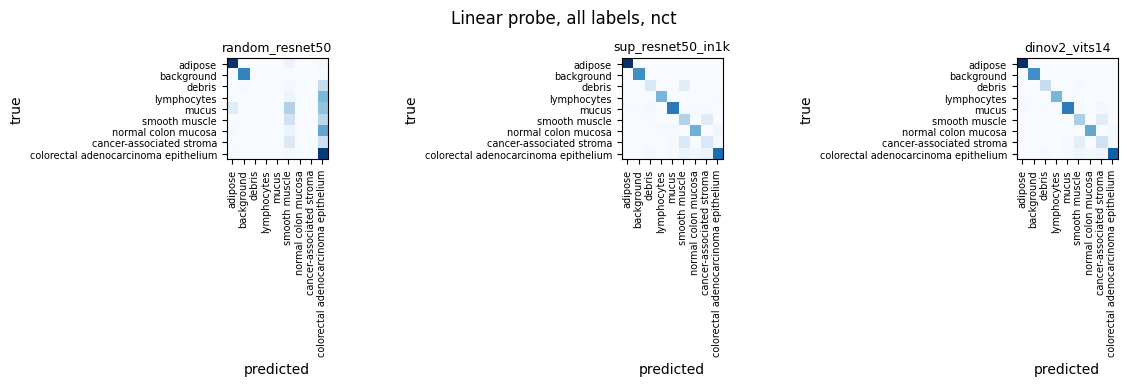

In [5]:
fig, axes = plt.subplots(1, len(PHASE1_BACKBONES), figsize=(12, 3.8))
for ax, name in zip(axes, PHASE1_BACKBONES):
    image = ax.imshow(matrices[name], cmap="Blues")
    ax.set_title(name, fontsize=9)
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
fig.suptitle(f"Linear probe, all labels, {DATASET}")
fig.tight_layout()
plt.show()


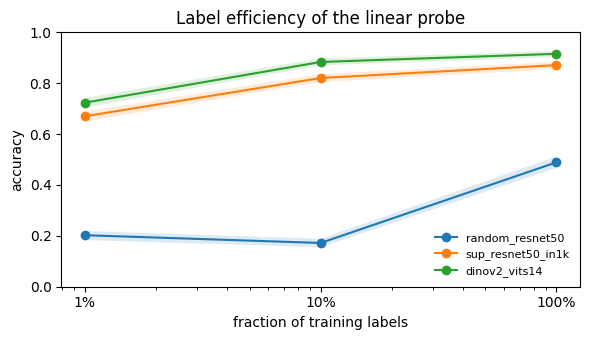

In [6]:
probe = results[(results["method"] == "linear_probe") & (results["metric"] == "accuracy")]
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in PHASE1_BACKBONES:
    block = probe[probe["backbone"] == name].sort_values("label_fraction")
    ax.plot(block["label_fraction"], block["value"], marker="o", label=name)
    ax.fill_between(block["label_fraction"], block["ci_low"], block["ci_high"], alpha=0.15)
ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1.0])
ax.set_xticklabels(["1%", "10%", "100%"])
ax.set_ylim(0, 1)
ax.set_xlabel("fraction of training labels")
ax.set_ylabel("accuracy")
ax.set_title("Label efficiency of the linear probe")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compa

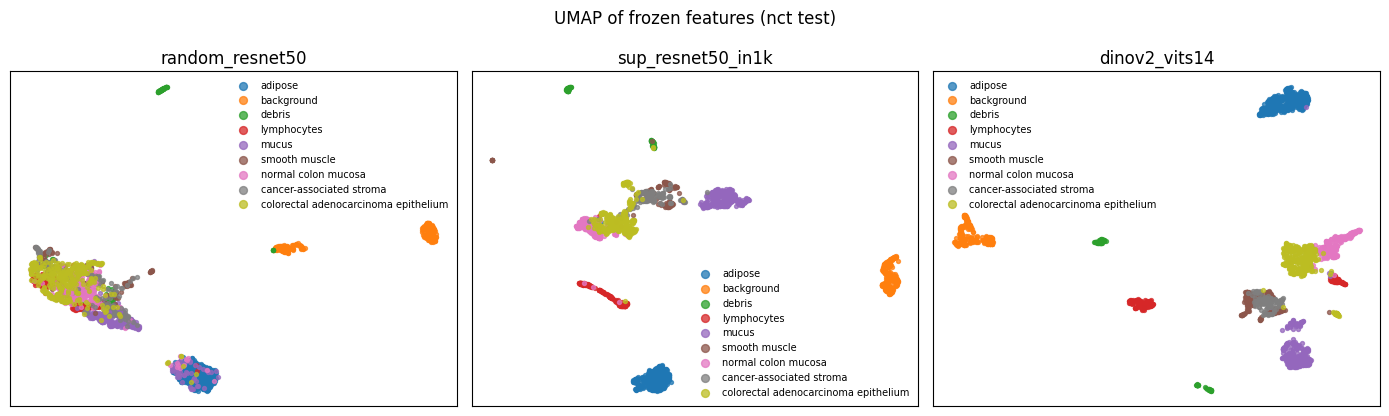

In [7]:
try:
    from ssl_demo.viz import plot_umap_by_class

    fig, axes = plt.subplots(1, len(PHASE1_BACKBONES), figsize=(14, 4.2))
    for ax, name in zip(axes, PHASE1_BACKBONES):
        test = stored[name]
        plot_umap_by_class(
            test.features,
            test.labels,
            CLASS_NAMES,
            seed=SEED,
            max_points=2000,
            title=name,
            ax=ax,
        )
    fig.suptitle(f"UMAP of frozen features ({DATASET} test)")
    fig.tight_layout()
    plt.show()
except ImportError as exc:
    print("UMAP skipped. Install umap-learn to draw this panel.", exc)


## What we learned

- kNN and a linear probe score frozen features. Nothing in the backbone was updated, so a change in accuracy is a change in the representation.
- The 1% / 10% / 100% probe is the label-efficiency argument: the interesting gap, when there is one, shows up before the labels run out.
- A random network that matches ImageNet or DINOv2 means the pipeline is broken (normalisation, a stale cache, or a head that ignores the features). The sanity line above is that check.

Table: `results/probe_nct.csv` with columns backbone, method, label_fraction, metric, value, ci_low, ci_high, plus the dataset name.
